[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/11_recommenders.ipynb)

*Machine Learning from Scratch · Notebook 11 of 13*

# Recommender Systems

Suggest what a user will like next: popularity baselines, similarity measures, user- and item-based collaborative filtering, content-based TF-IDF, matrix factorisation, market-basket rules, cold start, and the ranking metrics used to judge recommenders.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A recommender is a well-read friend: it remembers what you liked, notices who has similar taste, and suggests what they enjoyed next.

**What interviewers really test here:** User- vs item-based CF, cold start, implicit feedback, matrix factorisation, two-stage retrieval and ranking, and ranking metrics like NDCG.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What a recommender does *(Basics)*
- [ ] 2. Similarity: who is like whom *(Core)*
- [ ] 3. User-based and item-based collaborative filtering *(Core)*
- [ ] 4. Content-based and hybrid recommenders *(Core)*
- [ ] 5. Matrix factorisation and modern systems *(Advanced)*
- [ ] 6. Evaluating recommenders *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Families of recommenders

| Approach | Uses | Strength | Weakness |
| --- | --- | --- | --- |
| Popularity | counts | simple, strong baseline | not personal |
| User-based CF | similar users | intuitive | many users, sparse overlap |
| Item-based CF | similar items | stable, explainable | new items |
| Content-based | item features | handles new items | over-specialises |
| Matrix factorisation | latent factors | accurate, compact | cold start, less explainable |
| Two-stage neural | embeddings + ranker | scales to billions | complex |

### Ranking metrics

| Metric | Formula |
| --- | --- |
| Precision@k | relevant in top k ÷ k |
| Recall@k | relevant in top k ÷ all relevant |
| Hit rate@k | share of users with ≥ 1 relevant in top k |
| MRR | mean of 1 / rank of the first relevant item |
| DCG@k | Σ relᵢ / log₂(i + 1), i = 1..k |
| NDCG@k | DCG@k ÷ DCG@k of the ideal order |

### Association rules

- **Support**(A→B) = P(A ∧ B)
- **Confidence**(A→B) = P(B | A) = support(A ∧ B) / support(A)
- **Lift**(A→B) = confidence / P(B); 1 = independent, &gt; 1 = A raises the chance of B



The Apriori algorithm only grows itemsets whose subsets are already frequent, because support can only shrink as sets grow.

---
# Part 2: Lessons, step by step

## Lesson 1: What a recommender does

*Level: Basics*

Netflix rows, Amazon's "customers also bought", Spotify's weekly mix: a **recommender** ranks items a user hasn't seen by how likely they are to want them. The data is a **user × item matrix** that is almost entirely empty — a typical user has touched far less than 1% of the catalogue.




- **Explicit feedback**: star ratings. Clear but rare.
- **Implicit feedback**: clicks, plays, purchases, watch time. Plentiful but noisy — a missing click doesn't mean dislike.



Always start with the **popularity baseline** (most-interacted items the user hasn't seen). It's surprisingly strong, and every smarter method has to beat it.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

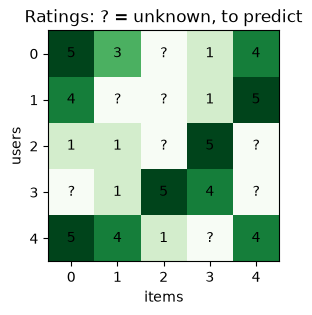

In [2]:
R = np.array([[5, 3, 0, 1, 4],
              [4, 0, 0, 1, 5],
              [1, 1, 0, 5, 0],
              [0, 1, 5, 4, 0],
              [5, 4, 1, 0, 4]], dtype=float)


def matrix_picture():
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.imshow(R, cmap="Greens", vmin=0, vmax=5)
    for (i, j), v in np.ndenumerate(R):
        ax.text(j, i, "?" if v == 0 else int(v), ha="center", va="center")
    ax.set_xlabel("items")
    ax.set_ylabel("users")
    ax.set_title("Ratings: ? = unknown, to predict")


matrix_picture()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 2: Similarity: who is like whom

*Level: Core*

Collaborative filtering rests on one idea: **people who agreed before will agree again**. To use it we need a similarity score.



| Measure | Formula | Use for |
| --- | --- | --- |
| Cosine | a·b / (‖a‖ ‖b‖) | rating or count vectors |
| Pearson (mean-centred) | cosine after subtracting each user's mean | harsh vs generous raters |
| Jaccard | \|A ∩ B\| / \|A ∪ B\| | yes/no interactions |



Centring matters: a user who rates everything 4–5 and one who rates everything 1–2 may love the same films. After subtracting their means, their *preferences* line up even though their numbers don't.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

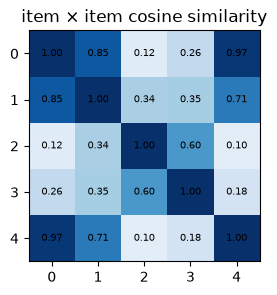

In [3]:
from sklearn.metrics.pairwise import cosine_similarity
R = np.array([[5, 3, 0, 1, 4],
              [4, 0, 0, 1, 5],
              [1, 1, 0, 5, 0],
              [0, 1, 5, 4, 0],
              [5, 4, 1, 0, 4]], dtype=float)


def item_similarity():
    S = cosine_similarity(R.T)
    fig, ax = plt.subplots(figsize=(3.6, 3))
    ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(S):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title("item × item cosine similarity")


item_similarity()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q12](#q12), [Q4](#q4), [Q3](#q3), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 3: User-based and item-based collaborative filtering

*Level: Core*

**User-based**: find the k users most similar to you who rated the item, and take their similarity-weighted average rating. **Item-based**: for each item you haven't seen, look at the items you *have* rated and weight your ratings by how similar those items are.



```python
S = cosine_similarity(R.T)                      # item × item
scores = (S[:, rated] @ R[user, rated]) / S[:, rated].sum(axis=1)
```



Item-based CF is usually preferred in production (Amazon popularised it): there are fewer items than users, item similarities change slowly so they can be computed overnight, and the result is easy to explain — "because you bought X".

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 4: Content-based and hybrid recommenders

*Level: Core*

**Content-based** methods recommend items whose *features* resemble what the user liked: genre, price, brand, or the words in a description (TF-IDF), or an embedding from a language model. They work for brand-new items with no ratings, but they can't surprise you — they only find more of the same.



The **cold-start problem**: a new user has no history, a new item has no ratings. Fixes: popularity for new users, content features for new items, asking a few onboarding questions. Real systems are **hybrids** that combine collaborative and content signals.

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 5: Matrix factorisation and modern systems

*Level: Advanced*

**Matrix factorisation** learns a short vector for each user and each item (say 50 numbers) so that their dot product ≈ the rating. The numbers become **latent factors** such as "how much action" or "how highbrow". The Netflix Prize was won largely with this. SVD gives the best low-rank approximation of a full matrix; for sparse ratings, methods like ALS or SGD fit only the known entries, with regularisation.



Large modern systems work in two stages: **candidate generation** (pull a few hundred items fast, often by nearest-neighbour search over embeddings — the same vector search used in RAG) and **ranking** (a gradient-boosted or neural model scores those candidates using many features), followed by business rules such as diversity and removing already-bought items.



**Market-basket analysis** finds items bought together: support (how common), confidence P(B | A), and **lift** = confidence / P(B). Lift above 1 means A really raises the chance of B.

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q8](#q8), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 6: Evaluating recommenders

*Level: Advanced*

Split by **time**: hold out each user's latest interactions and see if you'd have recommended them. Then measure:




- **Rating accuracy**: RMSE — only for explicit ratings, and rarely what the business cares about.
- **Ranking quality**: precision@k, recall@k, hit rate, MRR (how high the first hit is), **NDCG** (graded relevance with a discount for lower positions).
- **Beyond accuracy**: coverage (how much of the catalogue gets recommended), diversity, novelty — a system that recommends only bestsellers can score well and still be useless.



Offline metrics are only a filter; the final judge is an **online A/B test** on clicks, purchases or watch time.

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q16](#q16), [Q6](#q6), [Q18](#q18), [Q9](#q9), [Q10](#q10). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
R = [[5, 3, 0, 1, 4],
     [4, 0, 0, 1, 5],
     [1, 1, 0, 5, 0],
     [0, 1, 5, 4, 0],
     [5, 4, 1, 0, 4]]

from sklearn.metrics.pairwise import cosine_similarity

import math

from sklearn.metrics import ndcg_score, mean_squared_error, jaccard_score


<a id="q1"></a>
### Q1. Most Popular Unseen Items

🟢 Warm-up · *Popularity baseline*

Rank items by how many users rated them (ties: lower index first) and return the top `n` item indexes that `user` hasn't rated.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 2, n = 2` → `[4, 2]`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, n = 1` → `[1]`

In [ ]:
def popular(R, user, n):
    """
    Rank items by how many users rated them (ties: lower index first) and return
    the top n item indexes that user hasn't rated.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(popular, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 2, 2), [4, 2]),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 1), [1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count ratings per column in a loop, sort, skip seen ones.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy: `(R > 0).sum(axis=0)` and a stable `argsort`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count ratings per column in a loop, sort, skip seen ones.

```python
def popular(R, user, n):
    counts = [sum(1 for row in R if row[j] > 0) for j in range(len(R[0]))]
    order = sorted(range(len(counts)), key=lambda j: (-counts[j], j))
    return [j for j in order if R[user][j] == 0][:n]
```

**Cost:** O(ui + i log i) time, O(i) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** NumPy: `(R > 0).sum(axis=0)` and a stable `argsort`.

```python
def popular(R, user, n):
    A = np.array(R)
    order = np.argsort(-(A > 0).sum(axis=0), kind="stable")
    return [int(j) for j in order if A[user, j] == 0][:n]
```

**Cost:** O(ui + i log i) time, O(i) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count ratings per column in a loop, sort, skip seen ones. That costs O(ui + i log i) time and O(i) space."

"I can do better: NumPy: `(R > 0).sum(axis=0)` and a stable `argsort`. That's O(ui + i log i) time and O(i) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/most-popular-unseen-items)

<a id="q2"></a>
### Q2. Cosine Similarity of Two Users

🟢 Warm-up · *Angle between vectors*

Return the cosine similarity of users `a` and `b`'s rating rows (0 = not rated), rounded to 4.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 0, b = 1` → `0.8859`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 0, b = 2` → `0.3503`

In [ ]:
def user_cosine(R, a, b):
    """
    Return the cosine similarity of users a and b's rating rows (0 = not rated),
    rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(user_cosine, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 1), 0.8859),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 2), 0.3503),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dot product ÷ (length × length).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cosine_similarity`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Dot product ÷ (length × length).

```python
def user_cosine(R, a, b):
    x, y = R[a], R[b]
    dot = sum(p * q for p, q in zip(x, y))
    return round(dot / (math.sqrt(sum(p * p for p in x)) * math.sqrt(sum(q * q for q in y))), 4)
```

**Cost:** O(i) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cosine_similarity`.

```python
def user_cosine(R, a, b):
    A = np.array(R, float)
    return round(float(cosine_similarity(A[[a]], A[[b]])[0, 0]), 4)
```

**Cost:** O(i) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dot product ÷ (length × length). That costs O(i) time and O(1) space."

"I can do better: `cosine_similarity`. That's O(i) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/cosine-similarity-of-two-users)

<a id="q3"></a>
### Q3. Most Similar Item

🟢 Warm-up · *Item-item cosine*

Return the index of the item most similar to `item` by cosine similarity of rating columns (excluding itself; lowest index on ties).

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], item = 0` → `4`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], item = 2` → `3`

In [ ]:
def similar_item(R, item):
    """
    Return the index of the item most similar to item by cosine similarity of
    rating columns (excluding itself; lowest index on ties).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(similar_item, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0), 4),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 2), 3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Cosine between the item's column and every other column.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cosine_similarity(A.T)`, blank the diagonal, `argmax`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Cosine between the item's column and every other column.

```python
def similar_item(R, item):
    col = lambda j: [row[j] for row in R]
    x = col(item)
    best, best_s = None, -2
    for j in range(len(R[0])):
        if j == item:
            continue
        y = col(j)
        s = sum(p * q for p, q in zip(x, y)) / (math.sqrt(sum(p * p for p in x)) * math.sqrt(sum(q * q for q in y)))
        if s > best_s + 1e-12:
            best, best_s = j, s
    return best
```

**Cost:** O(ui) time, O(u) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cosine_similarity(A.T)`, blank the diagonal, `argmax`.

```python
def similar_item(R, item):
    S = cosine_similarity(np.array(R, float).T)
    np.fill_diagonal(S, -np.inf)
    return int(S[item].argmax())
```

**Cost:** O(u i²) time, O(i²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Cosine between the item's column and every other column. That costs O(ui) time and O(u) space."

"I can do better: `cosine_similarity(A.T)`, blank the diagonal, `argmax`. That's O(u i²) time and O(i²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/most-similar-item)

<a id="q4"></a>
### Q4. Jaccard Similarity for Clicks

🟢 Warm-up · *Implicit feedback*

For yes/no interactions, similarity = |both| ÷ |either|. Return the Jaccard similarity of users `a` and `b` (rated = interacted), rounded to 4.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 0, b = 1` → `0.75`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 2, b = 3` → `0.5`

In [ ]:
def jaccard(R, a, b):
    """
    For yes/no interactions, similarity = |both| ÷ |either|. Return the Jaccard
    similarity of users a and b (rated = interacted), rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(jaccard, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 1), 0.75),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 2, 3), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sets of rated items: intersection ÷ union.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`jaccard_score` on the boolean rows.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sets of rated items: intersection ÷ union.

```python
def jaccard(R, a, b):
    x = {j for j, v in enumerate(R[a]) if v}
    y = {j for j, v in enumerate(R[b]) if v}
    return round(len(x & y) / len(x | y), 4)
```

**Cost:** O(i) time, O(i) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `jaccard_score` on the boolean rows.

```python
def jaccard(R, a, b):
    A = np.array(R) > 0
    return round(float(jaccard_score(A[a], A[b])), 4)
```

**Cost:** O(i) time, O(i) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sets of rated items: intersection ÷ union. That costs O(i) time and O(i) space."

"I can do better: `jaccard_score` on the boolean rows. That's O(i) time and O(i) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/jaccard-similarity-for-clicks)

<a id="q5"></a>
### Q5. Precision@k and Recall@k

🟢 Warm-up · *Did we recommend the right things?*

Given a ranked list of recommendations and the set of relevant items, return `(precision@k, recall@k)` rounded to 4.

**Examples**

- `ranked = ['a', 'b', 'c', 'd', 'e'], relevant = ['b', 'e', 'x'], k = 3` → `(0.3333, 0.3333)`
- `ranked = ['a', 'b', 'c', 'd', 'e'], relevant = ['b', 'e', 'x'], k = 5` → `(0.4, 0.6667)`

In [ ]:
def precision_recall_at_k(ranked, relevant, k):
    """
    Given a ranked list of recommendations and the set of relevant items, return
    (precision@k, recall@k) rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(precision_recall_at_k, [
    ((['a', 'b', 'c', 'd', 'e'], ['b', 'e', 'x'], 3), (0.3333, 0.3333)),
    ((['a', 'b', 'c', 'd', 'e'], ['b', 'e', 'x'], 5), (0.4, 0.6667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count hits in the first k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set intersection.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count hits in the first k.

```python
def precision_recall_at_k(ranked, relevant, k):
    hits = 0
    for item in ranked[:k]:
        if item in relevant:
            hits += 1
    return (round(hits / k, 4), round(hits / len(relevant), 4))
```

**Cost:** O(k) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A set intersection.

```python
def precision_recall_at_k(ranked, relevant, k):
    hits = len(set(ranked[:k]) & set(relevant))
    return (round(hits / k, 4), round(hits / len(relevant), 4))
```

**Cost:** O(k) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count hits in the first k. That costs O(k) time and O(r) space."

"I can do better: A set intersection. That's O(k) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/precision-k-and-recall-k)

<a id="q6"></a>
### Q6. Hit Rate and Mean Reciprocal Rank

🟢 Warm-up · *Leave-one-out evaluation*

Each user has one held-out item and a ranked list. Return `(hit rate@k, MRR)`, where MRR uses 1/rank of the held-out item (0 if absent). Round to 4.

**Examples**

- `lists = [['a', 'b', 'c'], ['c', 'a', 'b'], ['b', 'c', 'd']], held_out = ['b', 'b', 'a'], k = 2` → `(0.3333, 0.2778)`

In [ ]:
def hit_mrr(lists, held_out, k):
    """
    Each user has one held-out item and a ranked list. Return (hit rate@k, MRR),
    where MRR uses 1/rank of the held-out item (0 if absent). Round to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hit_mrr, [
    (([['a', 'b', 'c'], ['c', 'a', 'b'], ['b', 'c', 'd']], ['b', 'b', 'a'], 2), (0.3333, 0.2778)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find each item's position with a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`list.index` in a comprehension, then NumPy means.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find each item's position with a loop.

```python
def hit_mrr(lists, held_out, k):
    hits = rr = 0
    for ranked, target in zip(lists, held_out):
        for pos, item in enumerate(ranked):
            if item == target:
                rr += 1 / (pos + 1)
                if pos < k:
                    hits += 1
                break
    n = len(lists)
    return (round(hits / n, 4), round(rr / n, 4))
```

**Cost:** O(u·L) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `list.index` in a comprehension, then NumPy means.

```python
def hit_mrr(lists, held_out, k):
    ranks = np.array([L.index(t) + 1 if t in L else np.inf for L, t in zip(lists, held_out)])
    return (round(float((ranks <= k).mean()), 4), round(float((1 / ranks).mean()), 4))
```

**Cost:** O(u·L) time, O(u) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find each item's position with a loop. That costs O(u·L) time and O(1) space."

"I can do better: `list.index` in a comprehension, then NumPy means. That's O(u·L) time and O(u) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/hit-rate-and-mean-reciprocal-rank)

<a id="q7"></a>
### Q7. Cold Start Fallback

🟢 Warm-up · *New users*

If `user` has rated fewer than `min_ratings` items, recommend the `n` most popular unseen items; otherwise use item-based scores. Return `(strategy, items)`.

**Examples**

- `R = [[5, 0, 0, 0, 0], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 0, min_ratings = 2, n = 2` → `('popular', [1, 3])`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, min_ratings = 2, n = 1` → `('item-based', [1])`

In [ ]:
def cold_start(R, user, min_ratings, n):
    """
    If user has rated fewer than min_ratings items, recommend the n most popular
    unseen items; otherwise use item-based scores. Return (strategy, items).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cold_start, [
    (([[5, 0, 0, 0, 0], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 2, 2), ('popular', [1, 3])),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 2, 1), ('item-based', [1])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if / else choosing between the popularity and item-based helpers.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The same choice as one conditional expression; `np.count_nonzero` counts the ratings.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** An if / else choosing between the popularity and item-based helpers.

```python
def pop_rank(R, user, n):
    A = np.array(R)
    order = np.argsort(-(A > 0).sum(axis=0), kind="stable")
    return [int(j) for j in order if A[user, j] == 0][:n]

def item_rank(R, user, n):
    A = np.array(R, float)
    S = cosine_similarity(A.T)
    rated = A[user] > 0
    scores = (S[:, rated] @ A[user, rated]) / S[:, rated].sum(axis=1)
    return [int(j) for j in np.argsort(-scores, kind="stable") if not rated[j]][:n]


def cold_start(R, user, min_ratings, n):
    if sum(1 for v in R[user] if v > 0) < min_ratings:
        return ("popular", pop_rank(R, user, n))
    return ("item-based", item_rank(R, user, n))
```

**Cost:** O(i² u) time, O(i²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** The same choice as one conditional expression; `np.count_nonzero` counts the ratings.

```python
def pop_rank(R, user, n):
    A = np.array(R)
    order = np.argsort(-(A > 0).sum(axis=0), kind="stable")
    return [int(j) for j in order if A[user, j] == 0][:n]

def item_rank(R, user, n):
    A = np.array(R, float)
    S = cosine_similarity(A.T)
    rated = A[user] > 0
    scores = (S[:, rated] @ A[user, rated]) / S[:, rated].sum(axis=1)
    return [int(j) for j in np.argsort(-scores, kind="stable") if not rated[j]][:n]


def cold_start(R, user, min_ratings, n):
    is_new = np.count_nonzero(R[user]) < min_ratings
    return ("popular", pop_rank(R, user, n)) if is_new else ("item-based", item_rank(R, user, n))
```

**Cost:** O(i² u) time, O(i²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if / else choosing between the popularity and item-based helpers. That costs O(i² u) time and O(i²) space."

"I can do better: The same choice as one conditional expression; `np.count_nonzero` counts the ratings. That's O(i² u) time and O(i²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/cold-start-fallback)

<a id="q8"></a>
### Q8. Frequently Bought Together

🟢 Warm-up · *Co-occurrence*

Return the pair of products (alphabetical) that appears together in the most baskets, with its count (alphabetically first pair on ties).

**Examples**

- `baskets = [['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']]` → `(('bread', 'butter'), 3)`

In [ ]:
from collections import Counter

from itertools import combinations

def top_pair(baskets):
    """
    Return the pair of products (alphabetical) that appears together in the most
    baskets, with its count (alphabetically first pair on ties).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_pair, [
    (([['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']],), (('bread', 'butter'), 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`combinations` of each sorted basket into a Counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A basket × product 0/1 matrix B; Bᵀ B counts every pair at once.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `combinations` of each sorted basket into a Counter.

```python
def top_pair(baskets):
    c = Counter()
    for b in baskets:
        for pair in combinations(sorted(set(b)), 2):
            c[pair] += 1
    best = min(c, key=lambda p: (-c[p], p))
    return (best, c[best])
```

**Cost:** O(b · k²) time, O(p²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A basket × product 0/1 matrix B; Bᵀ B counts every pair at once.

```python
def top_pair(baskets):
    B = pd.DataFrame([{p: 1 for p in b} for b in baskets]).fillna(0).astype(int)
    B = B[sorted(B.columns)]
    C = B.T @ B
    M = np.triu(C.to_numpy(), k=1)
    i, j = np.unravel_index(M.argmax(), M.shape)
    return ((C.index[i], C.columns[j]), int(M[i, j]))
```

**Cost:** O(b p²) time, O(p²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `combinations` of each sorted basket into a Counter. That costs O(b · k²) time and O(p²) space."

"I can do better: A basket × product 0/1 matrix B; Bᵀ B counts every pair at once. That's O(b p²) time and O(p²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/frequently-bought-together)

<a id="q9"></a>
### Q9. Catalogue Coverage

🟢 Warm-up · *Beyond accuracy*

Return the % of the catalogue (`n_items`) that appears in at least one user's recommendation list, rounded to 1.

**Examples**

- `lists = [['a', 'b'], ['a', 'c'], ['a', 'b']], n_items = 10` → `30.0`

In [ ]:
def coverage(lists, n_items):
    """
    Return the % of the catalogue (n_items) that appears in at least one user's
    recommendation list, rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(coverage, [
    (([['a', 'b'], ['a', 'c'], ['a', 'b']], 10), 30.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add every item to a set in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set comprehension.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Add every item to a set in a loop.

```python
def coverage(lists, n_items):
    seen = set()
    for L in lists:
        for item in L:
            seen.add(item)
    return round(len(seen) / n_items * 100, 1)
```

**Cost:** O(u k) time, O(items) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A set comprehension.

```python
def coverage(lists, n_items):
    return round(len({i for L in lists for i in L}) / n_items * 100, 1)
```

**Cost:** O(u k) time, O(items) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add every item to a set in a loop. That costs O(u k) time and O(items) space."

"I can do better: A set comprehension. That's O(u k) time and O(items) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/catalogue-coverage)

<a id="q10"></a>
### Q10. RMSE of Rating Predictions

🟢 Warm-up · *Rating accuracy*

Return the root mean squared error between true and predicted ratings, rounded to 4.

**Examples**

- `y = [4, 3, 5, 2], p = [3.5, 3, 4, 3]` → `0.75`

In [ ]:
def rmse(y, p):
    """
    Return the root mean squared error between true and predicted ratings,
    rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rmse, [
    (([4, 3, 5, 2], [3.5, 3, 4, 3]), 0.75),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over squared errors.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.metrics.mean_squared_error`, then the square root.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over squared errors.

```python
def rmse(y, p):
    return round(math.sqrt(sum((a - b) ** 2 for a, b in zip(y, p)) / len(y)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.metrics.mean_squared_error`, then the square root.

```python
def rmse(y, p):
    return round(float(np.sqrt(mean_squared_error(y, p))), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over squared errors. That costs O(n) time and O(1) space."

"I can do better: `sklearn.metrics.mean_squared_error`, then the square root. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/rmse-of-rating-predictions)

<a id="q11"></a>
### Q11. k Nearest Items

🟢 Warm-up · *NearestNeighbors with cosine*

Return the indexes of the `k` items closest to `item` by cosine distance of rating columns, closest first, excluding the item itself.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], item = 0, k = 2` → `[4, 1]`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], item = 3, k = 2` → `[2, 1]`

In [ ]:
from sklearn.neighbors import NearestNeighbors

def nearest_items(R, item, k):
    """
    Return the indexes of the k items closest to item by cosine distance of
    rating columns, closest first, excluding the item itself.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nearest_items, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 2), [4, 1]),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 3, 2), [2, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute every distance and sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`NearestNeighbors(metric='cosine').kneighbors`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute every distance and sort.

```python
def nearest_items(R, item, k):
    cols = [[row[j] for row in R] for j in range(len(R[0]))]
    x = cols[item]
    def dist(y):
        return 1 - sum(p * q for p, q in zip(x, y)) / (math.sqrt(sum(p * p for p in x)) * math.sqrt(sum(q * q for q in y)))
    others = [j for j in range(len(cols)) if j != item]
    return sorted(others, key=lambda j: (round(dist(cols[j]), 12), j))[:k]
```

**Cost:** O(ui + i log i) time, O(i) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `NearestNeighbors(metric='cosine').kneighbors`.

```python
def nearest_items(R, item, k):
    X = np.array(R, float).T
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
    _, idx = nn.kneighbors(X[[item]])
    return [int(j) for j in idx[0] if j != item][:k]
```

**Cost:** O(ui) time, O(i) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute every distance and sort. That costs O(ui + i log i) time and O(i) space."

"I can do better: `NearestNeighbors(metric='cosine').kneighbors`. That's O(ui) time and O(i) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/k-nearest-items)

<a id="q12"></a>
### Q12. Mean-Centred (Pearson) Similarity

🟡 Interview standard · *Handling harsh and generous raters*

Subtract each user's mean of their **rated** items, then take cosine over items both users rated. Return it rounded to 4 (0 if undefined).

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 0, b = 1` → `0.8836`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], a = 0, b = 2` → `-0.8561`

In [ ]:
def pearson_sim(R, a, b):
    """
    Subtract each user's mean of their rated items, then take cosine over items
    both users rated. Return it rounded to 4 (0 if undefined).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pearson_sim, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 1), 0.8836),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 0, 2), -0.8561),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Means over non-zero entries, then a loop over co-rated items.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Boolean masks select co-rated items; NumPy does the rest.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Means over non-zero entries, then a loop over co-rated items.

```python
def pearson_sim(R, a, b):
    x, y = R[a], R[b]
    mx = sum(v for v in x if v) / sum(1 for v in x if v)
    my = sum(v for v in y if v) / sum(1 for v in y if v)
    num = sx = sy = 0
    for p, q in zip(x, y):
        if p and q:
            num += (p - mx) * (q - my)
            sx += (p - mx) ** 2
            sy += (q - my) ** 2
    return round(num / math.sqrt(sx * sy), 4) if sx and sy else 0
```

**Cost:** O(i) time, O(i) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Boolean masks select co-rated items; NumPy does the rest.

```python
def pearson_sim(R, a, b):
    A = np.array(R, float)
    x, y = A[a], A[b]
    both = (x > 0) & (y > 0)
    dx, dy = x[both] - x[x > 0].mean(), y[both] - y[y > 0].mean()
    den = np.sqrt((dx ** 2).sum() * (dy ** 2).sum())
    return round(float(dx @ dy / den), 4) if den else 0
```

**Cost:** O(i) time, O(i) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Means over non-zero entries, then a loop over co-rated items. That costs O(i) time and O(i) space."

"I can do better: Boolean masks select co-rated items; NumPy does the rest. That's O(i) time and O(i) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/mean-centred-pearson-similarity)

<a id="q13"></a>
### Q13. User-Based Rating Prediction

🟡 Interview standard · *Neighbours' weighted average*

Predict `user`'s rating of `item` as the cosine-weighted average of the ratings from the `k` most similar users who rated it. Round to 4.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, item = 1, k = 2` → `3.4778`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 2, item = 4, k = 2` → `4.4327`

In [ ]:
def predict_user_based(R, user, item, k):
    """
    Predict user's rating of item as the cosine-weighted average of the ratings
    from the k most similar users who rated it. Round to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predict_user_based, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 1, 2), 3.4778),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 2, 4, 2), 4.4327),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score every other user, keep raters of the item, take the top k, weighted average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Similarity row from `cosine_similarity`, then NumPy masking and `argsort`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Score every other user, keep raters of the item, take the top k, weighted average.

```python
def predict_user_based(R, user, item, k):
    def cos(x, y):
        return sum(p * q for p, q in zip(x, y)) / (math.sqrt(sum(p * p for p in x)) * math.sqrt(sum(q * q for q in y)))
    cands = [(cos(R[user], R[v]), R[v][item]) for v in range(len(R)) if v != user and R[v][item] > 0]
    cands.sort(key=lambda t: -t[0])
    top = cands[:k]
    return round(sum(s * r for s, r in top) / sum(s for s, _ in top), 4)
```

**Cost:** O(u i) time, O(u) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Similarity row from `cosine_similarity`, then NumPy masking and `argsort`.

```python
def predict_user_based(R, user, item, k):
    A = np.array(R, float)
    sims = cosine_similarity(A[[user]], A)[0]
    raters = [v for v in np.argsort(-sims, kind="stable") if v != user and A[v, item] > 0][:k]
    w = sims[raters]
    return round(float(w @ A[raters, item] / w.sum()), 4)
```

**Cost:** O(u i) time, O(u) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score every other user, keep raters of the item, take the top k, weighted average. That costs O(u i) time and O(u) space."

"I can do better: Similarity row from `cosine_similarity`, then NumPy masking and `argsort`. That's O(u i) time and O(u) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/user-based-rating-prediction)

<a id="q14"></a>
### Q14. Item-Based Recommendations

🟡 Interview standard · *Score = ratings × item similarity*

Score each unrated item for `user` as Σ over rated items of rating × cosine(item, rated item) ÷ Σ similarities. Return the top `n` unrated item indexes.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, n = 2` → `[1, 2]`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 3, n = 1` → `[0]`

In [ ]:
def item_based(R, user, n):
    """
    Score each unrated item for user as Σ over rated items of rating ×
    cosine(item, rated item) ÷ Σ similarities. Return the top n unrated item
    indexes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(item_based, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 2), [1, 2]),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 3, 1), [0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Double loop over unrated × rated items.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One matrix product with the item-similarity matrix.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Double loop over unrated × rated items.

```python
def item_based(R, user, n):
    cols = [[row[j] for row in R] for j in range(len(R[0]))]
    cos = lambda x, y: sum(p * q for p, q in zip(x, y)) / (math.sqrt(sum(p * p for p in x)) * math.sqrt(sum(q * q for q in y)))
    rated = [j for j in range(len(cols)) if R[user][j] > 0]
    scores = {}
    for j in range(len(cols)):
        if R[user][j] == 0:
            sims = [cos(cols[j], cols[r]) for r in rated]
            scores[j] = sum(s * R[user][r] for s, r in zip(sims, rated)) / sum(sims)
    return sorted(scores, key=lambda j: (-scores[j], j))[:n]
```

**Cost:** O(i² u) time, O(i²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** One matrix product with the item-similarity matrix.

```python
def item_based(R, user, n):
    A = np.array(R, float)
    S = cosine_similarity(A.T)
    rated = A[user] > 0
    scores = (S[:, rated] @ A[user, rated]) / S[:, rated].sum(axis=1)
    order = np.argsort(-scores, kind="stable")
    return [int(j) for j in order if not rated[j]][:n]
```

**Cost:** O(i² u) time, O(i²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Double loop over unrated × rated items. That costs O(i² u) time and O(i²) space."

"I can do better: One matrix product with the item-similarity matrix. That's O(i² u) time and O(i²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/item-based-recommendations)

<a id="q15"></a>
### Q15. Content-Based: Similar Descriptions

🟡 Interview standard · *TF-IDF*

Using TF-IDF (smooth idf, L2-normalised rows, like sklearn) of item descriptions, return the index of the description most similar to `docs[i]`.

**Examples**

- `docs = ['space adventure with aliens', 'romantic comedy in paris', 'aliens invade earth adventure', 'paris love story comedy', 'documentary about space telescopes'], i = 0` → `2`
- `docs = ['space adventure with aliens', 'romantic comedy in paris', 'aliens invade earth adventure', 'paris love story comedy', 'documentary about space telescopes'], i = 1` → `3`

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def similar_doc(docs, i):
    """
    Using TF-IDF (smooth idf, L2-normalised rows, like sklearn) of item
    descriptions, return the index of the description most similar to docs[i].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(similar_doc, [
    ((['space adventure with aliens', 'romantic comedy in paris', 'aliens invade earth adventure', 'paris love story comedy', 'documentary about space telescopes'], 0), 2),
    ((['space adventure with aliens', 'romantic comedy in paris', 'aliens invade earth adventure', 'paris love story comedy', 'documentary about space telescopes'], 1), 3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build term counts and idf = ln((1 + n)/(1 + df)) + 1 by hand, normalise, then dot products.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`TfidfVectorizer` plus `cosine_similarity`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build term counts and idf = ln((1 + n)/(1 + df)) + 1 by hand, normalise, then dot products.

```python
def similar_doc(docs, i):
    toks = [d.split() for d in docs]
    vocab = sorted({w for t in toks for w in t})
    n = len(docs)
    idf = {w: math.log((1 + n) / (1 + sum(w in t for t in toks))) + 1 for w in vocab}
    vecs = []
    for t in toks:
        v = [t.count(w) * idf[w] for w in vocab]
        norm = math.sqrt(sum(x * x for x in v))
        vecs.append([x / norm for x in v])
    sims = [sum(a * b for a, b in zip(vecs[i], vecs[j])) if j != i else -1 for j in range(n)]
    return max(range(n), key=lambda j: sims[j])
```

**Cost:** O(n · words) time, O(n · vocab) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `TfidfVectorizer` plus `cosine_similarity`.

```python
def similar_doc(docs, i):
    X = TfidfVectorizer().fit_transform(docs)
    s = cosine_similarity(X[i], X)[0]
    s[i] = -1
    return int(s.argmax())
```

**Cost:** O(n · words) time, O(n · vocab) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build term counts and idf = ln((1 + n)/(1 + df)) + 1 by hand, normalise, then dot products. That costs O(n · words) time and O(n · vocab) space."

"I can do better: `TfidfVectorizer` plus `cosine_similarity`. That's O(n · words) time and O(n · vocab) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/content-based-similar-descriptions)

<a id="q16"></a>
### Q16. NDCG@k

🟡 Interview standard · *Position-aware quality*

Return NDCG@k for recommendation `scores` against graded `relevance` (same item order), using the standard log₂ discount. Round to 4.

**Examples**

- `relevance = [3, 2, 0, 1, 2], scores = [0.9, 0.8, 0.7, 0.6, 0.1], k = 3` → `0.81`
- `relevance = [3, 2, 0, 1, 2], scores = [0.1, 0.2, 0.9, 0.8, 0.3], k = 5` → `0.6417`

In [ ]:
def ndcg(relevance, scores, k):
    """
    Return NDCG@k for recommendation scores against graded relevance (same item
    order), using the standard log₂ discount. Round to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ndcg, [
    (([3, 2, 0, 1, 2], [0.9, 0.8, 0.7, 0.6, 0.1], 3), 0.81),
    (([3, 2, 0, 1, 2], [0.1, 0.2, 0.9, 0.8, 0.3], 5), 0.6417),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

DCG = Σ rel / log₂(rank + 1) over the top k by score; divide by the DCG of the ideal order.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.metrics.ndcg_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** DCG = Σ rel / log₂(rank + 1) over the top k by score; divide by the DCG of the ideal order.

```python
def ndcg(relevance, scores, k):
    order = sorted(range(len(scores)), key=lambda i: -scores[i])[:k]
    dcg = sum(relevance[i] / math.log2(r + 2) for r, i in enumerate(order))
    ideal = sorted(relevance, reverse=True)[:k]
    idcg = sum(rel / math.log2(r + 2) for r, rel in enumerate(ideal))
    return round(dcg / idcg, 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.metrics.ndcg_score`.

```python
def ndcg(relevance, scores, k):
    return round(float(ndcg_score([relevance], [scores], k=k)), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: DCG = Σ rel / log₂(rank + 1) over the top k by score; divide by the DCG of the ideal order. That costs O(n log n) time and O(n) space."

"I can do better: `sklearn.metrics.ndcg_score`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/ndcg-k)

<a id="q17"></a>
### Q17. Association Rule Metrics

🟡 Interview standard · *Support, confidence, lift*

For the rule A → B return `(support, confidence, lift)` rounded to 4: support = P(A and B), confidence = P(B | A), lift = confidence ÷ P(B).

**Examples**

- `baskets = [['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']], a = 'butter', b = 'bread'` → `(0.6, 1.0, 1.25)`
- `baskets = [['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']], a = 'milk', b = 'jam'` → `(0.2, 0.3333, 1.6667)`

In [ ]:
def rule(baskets, a, b):
    """
    For the rule A → B return (support, confidence, lift) rounded to 4: support
    = P(A and B), confidence = P(B | A), lift = confidence ÷ P(B).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rule, [
    (([['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']], 'butter', 'bread'), (0.6, 1.0, 1.25)),
    (([['bread', 'milk'], ['bread', 'butter', 'milk'], ['beer', 'chips'], ['bread', 'butter'], ['milk', 'butter', 'bread', 'jam']], 'milk', 'jam'), (0.2, 0.3333, 1.6667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count baskets with A, with B, with both.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Boolean columns of a one-hot basket DataFrame, then means.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count baskets with A, with B, with both.

```python
def rule(baskets, a, b):
    n = len(baskets)
    na = sum(a in x for x in baskets)
    nb = sum(b in x for x in baskets)
    nab = sum(a in x and b in x for x in baskets)
    conf = nab / na
    return (round(nab / n, 4), round(conf, 4), round(conf / (nb / n), 4))
```

**Cost:** O(b k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Boolean columns of a one-hot basket DataFrame, then means.

```python
def rule(baskets, a, b):
    B = pd.DataFrame([{p: True for p in x} for x in baskets]).fillna(False).astype(bool)
    both = (B[a] & B[b]).mean()
    conf = both / B[a].mean()
    return (round(both, 4), round(conf, 4), round(conf / B[b].mean(), 4))
```

**Cost:** O(b p) time, O(b p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count baskets with A, with B, with both. That costs O(b k) time and O(1) space."

"I can do better: Boolean columns of a one-hot basket DataFrame, then means. That's O(b p) time and O(b p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/association-rule-metrics)

<a id="q18"></a>
### Q18. Leave-Last-Out Split

🟡 Interview standard · *Time-aware evaluation*

`events` are (user, item, time). Hold out each user's latest event as test (users with one event stay entirely in train). Return `(train size, test pairs sorted)`.

**Examples**

- `events = [('u1', 'a', 1), ('u1', 'b', 5), ('u2', 'a', 2), ('u1', 'c', 3), ('u2', 'c', 9), ('u3', 'b', 4)]` → `(4, [('u1', 'b'), ('u2', 'c')])`

In [ ]:
def leave_last_out(events):
    """
    events are (user, item, time). Hold out each user's latest event as test
    (users with one event stay entirely in train). Return (train size, test
    pairs sorted).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leave_last_out, [
    (([('u1', 'a', 1), ('u1', 'b', 5), ('u2', 'a', 2), ('u1', 'c', 3), ('u2', 'c', 9), ('u3', 'b', 4)],), (4, [('u1', 'b'), ('u2', 'c')])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find each user's max time in a dict, then split.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('user')['time'].transform('max')` plus a count filter.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find each user's max time in a dict, then split.

```python
def leave_last_out(events):
    last, count = {}, {}
    for u, i, t in events:
        count[u] = count.get(u, 0) + 1
        if u not in last or t > last[u][1]:
            last[u] = (i, t)
    test = sorted((u, last[u][0]) for u in last if count[u] > 1)
    return (len(events) - len(test), test)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `groupby('user')['time'].transform('max')` plus a count filter.

```python
def leave_last_out(events):
    df = pd.DataFrame(events, columns=["user", "item", "time"])
    is_last = df["time"] == df.groupby("user")["time"].transform("max")
    multi = df.groupby("user")["item"].transform("size") > 1
    test = df[is_last & multi]
    return (len(df) - len(test), sorted(zip(test["user"], test["item"])))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find each user's max time in a dict, then split. That costs O(n) time and O(n) space."

"I can do better: `groupby('user')['time'].transform('max')` plus a count filter. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/leave-last-out-split)

<a id="q19"></a>
### Q19. Baseline Predictor With Biases

🟡 Interview standard · *μ + user bias + item bias*

Predict rating = global mean + (user's mean − global mean) + (item's mean − global mean), using only rated (non-zero) entries. Clip to [1, 5] and round to 4.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, item = 1` → `2.4069`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 2, item = 2` → `2.1569`

In [ ]:
def bias_predict(R, user, item):
    """
    Predict rating = global mean + (user's mean − global mean) + (item's mean −
    global mean), using only rated (non-zero) entries. Clip to [1, 5] and round
    to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bias_predict, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 1), 2.4069),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 2, 2), 2.1569),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three averages with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A masked NumPy array: `np.nanmean` over rows and columns.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Three averages with loops.

```python
def bias_predict(R, user, item):
    vals = [v for row in R for v in row if v]
    mu = sum(vals) / len(vals)
    ur = [v for v in R[user] if v]
    ir = [row[item] for row in R if row[item]]
    p = mu + (sum(ur) / len(ur) - mu) + (sum(ir) / len(ir) - mu)
    return round(min(5, max(1, p)), 4)
```

**Cost:** O(ui) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A masked NumPy array: `np.nanmean` over rows and columns.

```python
def bias_predict(R, user, item):
    A = np.array(R, float)
    A[A == 0] = np.nan
    mu = np.nanmean(A)
    p = mu + (np.nanmean(A[user]) - mu) + (np.nanmean(A[:, item]) - mu)
    return round(float(np.clip(p, 1, 5)), 4)
```

**Cost:** O(ui) time, O(ui) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three averages with loops. That costs O(ui) time and O(1) space."

"I can do better: A masked NumPy array: `np.nanmean` over rows and columns. That's O(ui) time and O(ui) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/baseline-predictor-with-biases)

<a id="q20"></a>
### Q20. Rank-1 Matrix Factorisation

🔴 Stretch · *Latent factors*

Approximate the ratings matrix (0s included) by its best rank-1 matrix σ·u·vᵀ and return the reconstructed value at (`user`, `item`), rounded to 4.

**Examples**

- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 1, item = 1` → `2.1921`
- `R = [[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], user = 3, item = 0` → `1.1804`

In [ ]:
def rank1(R, user, item):
    """
    Approximate the ratings matrix (0s included) by its best rank-1 matrix
    σ·u·vᵀ and return the reconstructed value at (user, item), rounded to 4.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rank1, [
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 1, 1), 2.1921),
    (([[5, 3, 0, 1, 4], [4, 0, 0, 1, 5], [1, 1, 0, 5, 0], [0, 1, 5, 4, 0], [5, 4, 1, 0, 4]], 3, 0), 1.1804),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Power iteration: repeat v ← AᵀAv / ‖AᵀAv‖ until it settles; then u = Av/σ.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.svd` and keep the largest singular value.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Power iteration: repeat v ← AᵀAv / ‖AᵀAv‖ until it settles; then u = Av/σ.

```python
def rank1(R, user, item):
    A = np.array(R, float)
    v = np.ones(A.shape[1])
    for _ in range(500):
        w = A.T @ (A @ v)
        v = w / math.sqrt(float(w @ w))
    Av = A @ v
    sigma = math.sqrt(float(Av @ Av))
    u = Av / sigma
    return round(float(sigma * u[user] * v[item]), 4)
```

**Cost:** O(iters · ui) time, O(u + i) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.linalg.svd` and keep the largest singular value.

```python
def rank1(R, user, item):
    U, s, Vt = np.linalg.svd(np.array(R, float), full_matrices=False)
    return round(float(s[0] * U[user, 0] * Vt[0, item]), 4)
```

**Cost:** O(ui · min(u, i)) time, O(ui) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Power iteration: repeat v ← AᵀAv / ‖AᵀAv‖ until it settles; then u = Av/σ. That costs O(iters · ui) time and O(u + i) space."

"I can do better: `np.linalg.svd` and keep the largest singular value. That's O(ui · min(u, i)) time and O(ui) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/recommenders/rank-1-matrix-factorisation)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. User-based or item-based CF?</b></summary>

Item-based is usually more practical: item–item similarities are fewer, more stable and can be precomputed, and recommendations are easy to explain.

</details>

<details>
<summary><b>2. How do you handle cold start?</b></summary>

Popular or trending items and short onboarding questions for new users; content features or embeddings for new items; and exploration (showing new items to some users) to collect data.

</details>

<details>
<summary><b>3. Why not just optimise RMSE?</b></summary>

Users see a ranked list, not predicted stars. Ranking metrics (NDCG, recall@k) and online business metrics matter more; a model can have lower RMSE and still rank worse.

</details>

<details>
<summary><b>4. What is implicit feedback and why is it tricky?</b></summary>

Behaviour such as clicks and plays. It's abundant, but you only observe positives — an unclicked item might be disliked or simply unseen — so missing values can't be treated as negatives without care.

</details>

<details>
<summary><b>5. How do large platforms serve recommendations quickly?</b></summary>

Two stages: fast candidate generation using approximate nearest-neighbour search over embeddings, then a heavier ranking model on a few hundred candidates, with caching of precomputed results.

</details>

<details>
<summary><b>6. What is popularity bias?</b></summary>

Popular items get recommended more, so they get more interactions, so they get recommended even more. It hurts diversity and new items; counter it with re-ranking for diversity and exploration.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What a recommender does
- [ ] I can explain: Similarity: who is like whom
- [ ] I can explain: User-based and item-based collaborative filtering
- [ ] I can explain: Content-based and hybrid recommenders
- [ ] I can explain: Matrix factorisation and modern systems
- [ ] I can explain: Evaluating recommenders

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) NDCG@k
- [ ] [Q17](#q17) Association Rule Metrics
- [ ] [Q18](#q18) Leave-Last-Out Split
- [ ] [Q19](#q19) Baseline Predictor With Biases
- [ ] [Q20](#q20) Rank-1 Matrix Factorisation

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.